In [104]:
print("Hello ECG ML")

Hello ECG ML


In [105]:
import sys

print(sys.version)
print(sys.executable)

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
/usr/bin/python3


In [106]:
%pip install wfdb scipy scikit-learn matplotlib pandas

In [107]:
import wfdb
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
import pandas as pd

print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)

NumPy version: 2.1.3
SciPy version: 1.16.3
Scikit-learn version: 1.6.1


In [108]:
record = wfdb.rdrecord("100", pn_dir="mitdb")
annotation = wfdb.rdann("100", "atr", pn_dir="mitdb")

signal = record.p_signal[:,0]


print("Recording loaded successfully!")
print("Signal shape:", signal.shape)
print("Sampling frequency:", record.fs, "Hz")
print("Number of annotations:", len(annotation.sample))
print("First 10 beat labels:", annotation.symbol[:10])

Recording loaded successfully!
Signal shape: (650000,)
Sampling frequency: 360 Hz
Number of annotations: 2274
First 10 beat labels: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


In [109]:
print("signal data type:", signal.dtype)
print("Total measurement:", len(signal))
print("Minimum value", signal.min())
print("Maximum value:", signal.max())
print("First 10 measurements:", signal[:10])

signal data type: float64
Total measurement: 650000
Minimum value -2.715
Maximum value: 1.435
First 10 measurements: [-0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.145 -0.12  -0.135]


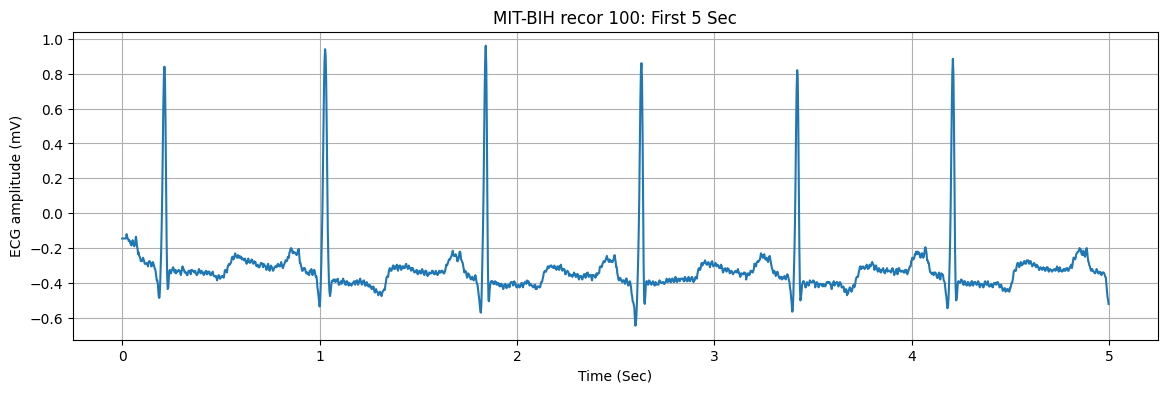

In [110]:
import matplotlib.pyplot as plt

seconds = 5
samples = int(seconds * record.fs)

time = np.arange(samples) / record.fs

plt.figure(figsize=(14,4))
plt.plot(time,signal[:samples])
plt.xlabel("Time (Sec)")
plt.ylabel("ECG amplitude (mV)")
plt.title("MIT-BIH recor 100: First 5 Sec")
plt.grid(True)
plt.show()

In [111]:
#expert labels for annotated beats
print("First 15 annotation sample positions:")
print(annotation.sample[:15])

print("\nFirst 15 annotation symbols:")
print(annotation.symbol[:15])

print("\nFirst 15 annotation times (seconds):")
print(np.round(annotation.sample[:15] / record.fs, 3))

First 15 annotation sample positions:
[  18   77  370  662  946 1231 1515 1809 2044 2402 2706 2998 3282 3560
 3862]

First 15 annotation symbols:
['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N']

First 15 annotation times (seconds):
[ 0.05   0.214  1.028  1.839  2.628  3.419  4.208  5.025  5.678  6.672
  7.517  8.328  9.117  9.889 10.728]


In [112]:
# Count how often each annotation symbol appears
from collections import Counter

label_counts = Counter(annotation.symbol)

# Print the most common labels
print(label_counts.most_common())

[('N', 2239), ('A', 33), ('+', 1), ('V', 1)]


In [113]:
# Create a filter that keeps frequencies from 0.5 to 40 Hz
from scipy.signal import butter, filtfilt

# Create a band-pass filter that keeps frequencies from 0.5 to 40 Hz.
# Below 0.5 Hz: removes much of the slow baseline drift caused by
# breathing, body movement, and changes in electrode contact.
# Above 40 Hz: reduces high-frequency noise, such as muscle activity
# and electrical interference, while preserving many important ECG features.
b, a = butter(3, [0.5, 40], btype="bandpass", fs=record.fs)

# Apply the filter to smooth unwanted noise in the ECG signal.
filtered_signal = filtfilt(b, a, signal)

# Check that filtering did not change the number of samples.
print("Original samples:", len(signal))
print("Filtered samples:", len(filtered_signal))

Original samples: 650000
Filtered samples: 650000


In [114]:
# Group ECG annotation symbols into five AAMI classes
AAMI = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q"
}

# Display the label mapping
print(AAMI)

{'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F', '/': 'Q', 'f': 'Q', 'Q': 'Q'}


In [115]:
# Extract fixed-length heartbeat windows from the filtered ECG
X, y = [], []

for peak, symbol in zip(annotation.sample, annotation.symbol):
    # Skip unsupported labels and beats too close to the signal edges
    if symbol not in AAMI or peak < 90 or peak >= len(filtered_signal) - 162:
        continue

    # Save the waveform window and its class label
    X.append(filtered_signal[peak - 90:peak + 162])
    y.append(AAMI[symbol])

# Convert the lists into NumPy arrays
X = np.array(X)
y = np.array(y)

print("Heartbeat data shape:", X.shape)
print("Label data shape:", y.shape)

Heartbeat data shape: (2271, 252)
Label data shape: (2271,)


In [116]:
# Count the number of extracted beats in each class
from collections import Counter

class_counts = Counter(y)

# Display the counts
for label, count in sorted(class_counts.items()):
    print(f"Class {label}: {count} beats")

Class N: 2237 beats
Class S: 33 beats
Class V: 1 beats


In [117]:
# Define the classic DS1 training and DS2 test record lists
DS1 = [
    "101", "106", "108", "109", "112", "114", "115", "116",
    "118", "119", "122", "124", "201", "203", "205", "207",
    "208", "209", "215", "220", "223", "230"
]

DS2 = [
    "100", "103", "105", "111", "113", "117", "121", "123",
    "200", "202", "210", "212", "213", "214", "219", "221",
    "222", "228", "231", "232", "233", "234"
]

# Check the number of records in each group
print("Training records:", len(DS1))
print("Test records:", len(DS2))
print("Records shared between groups:", set(DS1) & set(DS2))

Training records: 22
Test records: 22
Records shared between groups: set()


In [118]:
# Load and filter a record, then extract labeled heartbeat windows
from scipy.signal import butter, filtfilt
import wfdb
import numpy as np

b, a = butter(3, [0.5, 40], btype="bandpass", fs=360)

def load_beats(record_id):
    # Read the ECG signal and expert annotations
    record = wfdb.rdrecord(record_id, pn_dir="mitdb")
    annotation = wfdb.rdann(record_id, "atr", pn_dir="mitdb")

    # Filter the ECG signal
    signal = filtfilt(b, a, record.p_signal[:, 0])

    X, y = [], []

    # Extract one fixed-length window per supported beat
    for peak, symbol in zip(annotation.sample, annotation.symbol):
        if symbol not in AAMI or peak < 90 or peak >= len(signal) - 162:
            continue

        X.append(signal[peak - 90:peak + 162])
        y.append(AAMI[symbol])

    return np.asarray(X), np.asarray(y)

# Test the function on one training record
X_check, y_check = load_beats(DS1[0])

print("Record:", DS1[0])
print("Heartbeat shape:", X_check.shape)
print("Labels shape:", y_check.shape)

Record: 101
Heartbeat shape: (1864, 252)
Labels shape: (1864,)


In [119]:
# Load all records and keep the training and test groups separate
def load_group(record_ids):
    X_all, y_all = [], []

    for record_id in record_ids:
        X_record, y_record = load_beats(record_id)

        X_all.extend(X_record)
        y_all.extend(y_record)

        print(record_id, ":", len(y_record), "beats")

    return np.asarray(X_all), np.asarray(y_all)

# Build the training and test datasets
X_train, y_train = load_group(DS1)
X_test, y_test = load_group(DS2)

# Display the dataset sizes
print("\nTraining data:", X_train.shape, y_train.shape)
print("Test data:", X_test.shape, y_test.shape)

101 : 1864 beats
106 : 2027 beats
108 : 1762 beats
109 : 2531 beats
112 : 2538 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
118 : 2277 beats
119 : 1987 beats
122 : 2475 beats
124 : 1618 beats
201 : 1963 beats
203 : 2980 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
215 : 3362 beats
220 : 2046 beats
223 : 2604 beats
230 : 2255 beats
100 : 2271 beats
103 : 2083 beats
105 : 2572 beats
111 : 2124 beats
113 : 1794 beats
117 : 1534 beats
121 : 1862 beats
123 : 1517 beats
200 : 2600 beats
202 : 2135 beats
210 : 2648 beats
212 : 2747 beats
213 : 3250 beats
214 : 2260 beats
219 : 2154 beats
221 : 2427 beats
222 : 2481 beats
228 : 2053 beats
231 : 1570 beats
232 : 1780 beats
233 : 3077 beats
234 : 2753 beats

Training data: (51002, 252) (51002,)
Test data: (49692, 252) (49692,)


In [120]:
# Correct the annotation-to-AAMI class mapping
AAMI = {
    "N": "N", "L": "N", "R": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "e": "S", "j": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q", "U": "Q"
}

# Display the corrected mapping
print("Corrected AAMI mapping:", AAMI)

Corrected AAMI mapping: {'N': 'N', 'L': 'N', 'R': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'e': 'S', 'j': 'S', 'V': 'V', 'E': 'V', 'F': 'F', '/': 'Q', 'f': 'Q', 'Q': 'Q', 'U': 'Q'}


In [121]:
# Keep the standard training records
DS1 = [
    "101", "106", "108", "109", "112", "114", "115", "116",
    "118", "119", "122", "124", "201", "203", "205", "207",
    "208", "209", "215", "220", "223", "230"
]

# Exclude record 202 because its patient is already in training
DS2 = [
    "100", "103", "105", "111", "113", "117", "121", "123",
    "200", "210", "212", "213", "214", "219", "221", "222",
    "228", "231", "232", "233", "234"
]

# Check the updated split
print("Training records:", len(DS1))
print("Test records:", len(DS2))
print("Shared record IDs:", set(DS1) & set(DS2))
print("Record 202 in test set:", "202" in DS2)

Training records: 22
Test records: 21
Shared record IDs: set()
Record 202 in test set: False


In [122]:
# Load, filter, and extract supported heartbeat classes
def load_beats(record_id):
    record = wfdb.rdrecord(record_id, pn_dir="mitdb")
    annotation = wfdb.rdann(record_id, "atr", pn_dir="mitdb")

    # Filter the first ECG channel
    signal = filtfilt(b, a, record.p_signal[:, 0])

    X, y = [], []

    for peak, symbol in zip(annotation.sample, annotation.symbol):
        # Skip paced beats and unsupported annotations
        if symbol == "P":
            continue
        if symbol not in AAMI or peak < 90 or peak >= len(signal) - 162:
            continue

        # Save the beat waveform and its corrected label
        X.append(signal[peak - 90:peak + 162])
        y.append(AAMI[symbol])

    return np.asarray(X), np.asarray(y)

In [123]:
# Rebuild training and testing data using the corrected function
X_train, y_train = load_group(DS1)
X_test, y_test = load_group(DS2)

# Check the updated dataset sizes
print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

101 : 1864 beats
106 : 2027 beats
108 : 1762 beats
109 : 2531 beats
112 : 2538 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
118 : 2277 beats
119 : 1987 beats
122 : 2475 beats
124 : 1618 beats
201 : 1963 beats
203 : 2980 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
215 : 3362 beats
220 : 2046 beats
223 : 2604 beats
230 : 2255 beats
100 : 2271 beats
103 : 2083 beats
105 : 2572 beats
111 : 2124 beats
113 : 1794 beats
117 : 1534 beats
121 : 1862 beats
123 : 1517 beats
200 : 2600 beats
210 : 2648 beats
212 : 2747 beats
213 : 3250 beats
214 : 2260 beats
219 : 2154 beats
221 : 2427 beats
222 : 2481 beats
228 : 2053 beats
231 : 1570 beats
232 : 1780 beats
233 : 3077 beats
234 : 2753 beats
Training: (51002, 252) (51002,)
Testing: (47557, 252) (47557,)


In [124]:
# Count heartbeat classes in both datasets
from collections import Counter

print("Training class counts:")
print(Counter(y_train))

print("\nTesting class counts:")
print(Counter(y_test))

Training class counts:
Counter({np.str_('N'): 45816, np.str_('V'): 3788, np.str_('S'): 976, np.str_('F'): 414, np.str_('Q'): 8})

Testing class counts:
Counter({np.str_('N'): 41967, np.str_('V'): 3201, np.str_('S'): 1995, np.str_('F'): 387, np.str_('Q'): 7})


In [125]:
# Calculate each class's percentage of the dataset
def show_class_percentages(labels):
    counts = Counter(labels)
    total = len(labels)

    for label, count in sorted(counts.items()):
        print(f"{label}: {count} beats ({count / total * 100:.2f}%)")

show_class_percentages(y_train)

F: 414 beats (0.81%)
N: 45816 beats (89.83%)
Q: 8 beats (0.02%)
S: 976 beats (1.91%)
V: 3788 beats (7.43%)


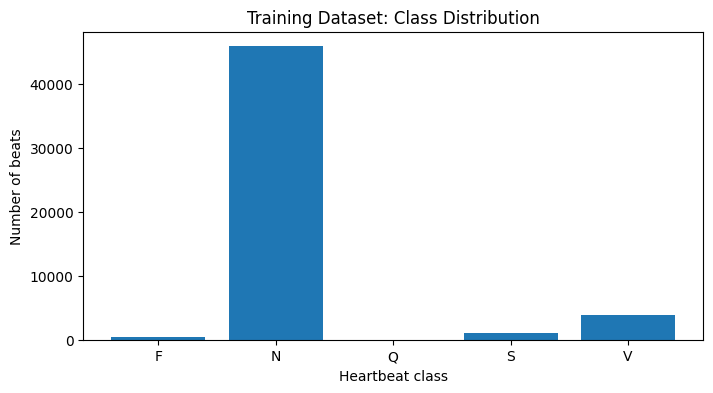

In [126]:
# Plot the number of training examples in each class
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(y_train)
labels = sorted(counts.keys())
values = [counts[label] for label in labels]

plt.figure(figsize=(8, 4))
plt.bar(labels, values)
plt.xlabel("Heartbeat class")
plt.ylabel("Number of beats")
plt.title("Training Dataset: Class Distribution")
plt.show()

In [127]:
# Check the data before training
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)
print("Classes:", sorted(set(y_train)))

Training features: (51002, 252)
Training labels: (51002,)
Test features: (47557, 252)
Test labels: (47557,)
Classes: [np.str_('F'), np.str_('N'), np.str_('Q'), np.str_('S'), np.str_('V')]


In [128]:
# Train a Random Forest that accounts for class imbalance
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Learn patterns from the training heartbeats
model.fit(X_train, y_train)

print("Random Forest training complete!")

Random Forest training complete!


In [129]:
# Evaluate predictions on the test dataset
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score

y_pred = model.predict(X_test)

# Print the main performance metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))

# Show precision, recall and F1 for each class
print(classification_report(
    y_test,
    y_pred,
    labels=["N", "S", "V", "F", "Q"],
    zero_division=0
))

# Show correct and incorrect predictions by class
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=["N", "S", "V", "F", "Q"]))

Accuracy: 0.9054
Macro F1: 0.3343
              precision    recall  f1-score   support

           N       0.93      0.97      0.95     41967
           S       0.02      0.00      0.00      1995
           V       0.66      0.79      0.72      3201
           F       0.00      0.00      0.00       387
           Q       0.00      0.00      0.00         7

    accuracy                           0.91     47557
   macro avg       0.32      0.35      0.33     47557
weighted avg       0.87      0.91      0.89     47557

Confusion matrix:
[[40528   141  1261    37     0]
 [ 1992     3     0     0     0]
 [  667     4  2529     1     0]
 [  362     0    25     0     0]
 [    7     0     0     0     0]]


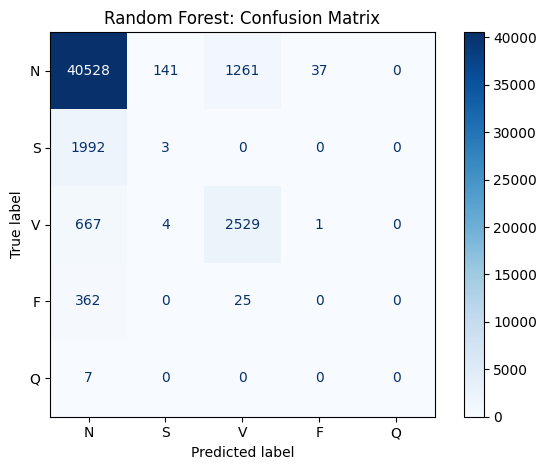

In [130]:
# Plot the confusion matrix as a heatmap
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["N", "S", "V", "F", "Q"],
    display_labels=["N", "S", "V", "F", "Q"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest: Confusion Matrix")
plt.tight_layout()
plt.show()

In [131]:
# Save the baseline metrics for later model comparisons
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

baseline_results = pd.DataFrame([{
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )
}])

baseline_results.to_csv("baseline_results.csv", index=False)

print(baseline_results)
print("Saved baseline_results.csv")

           model  accuracy  macro_f1
0  Random Forest   0.90544  0.334298
Saved baseline_results.csv


In [134]:
# Download the saved results to your computer
from google.colab import files
files.download("baseline_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [135]:
# Calculate RR intervals from annotated beat positions
def get_rr_features(record_id):
    # Read the ECG annotations
    ann = wfdb.rdann(record_id, "atr", pn_dir="mitdb")

    # Keep only annotations with supported heartbeat labels
    beats = [
        (peak, AAMI[symbol])
        for peak, symbol in zip(ann.sample, ann.symbol)
        if symbol in AAMI
    ]

    peaks = np.array([beat[0] for beat in beats])

    # Calculate intervals in seconds
    rr_prev = np.diff(peaks, prepend=peaks[0]) / 360
    rr_next = np.diff(peaks, append=peaks[-1]) / 360

    # Combine previous and next intervals
    return np.column_stack((rr_prev, rr_next))

# Test the feature extraction on one record
rr_check = get_rr_features("101")

print("RR feature shape:", rr_check.shape)
print("First five RR feature pairs:\n", rr_check[:5])

RR feature shape: (1865, 2)
First five RR feature pairs:
 [[0.         0.86944444]
 [0.86944444 0.875     ]
 [0.875      0.89166667]
 [0.89166667 0.93333333]
 [0.93333333 0.95555556]]


In [136]:
# Check record IDs and known split constraints
print("Training record count:", len(DS1))
print("Testing record count:", len(DS2))
print("Shared record IDs:", set(DS1) & set(DS2))

# Check the known paired records
print("Record 201 in training:", "201" in DS1)
print("Record 202 in testing:", "202" in DS2)

Training record count: 22
Testing record count: 21
Shared record IDs: set()
Record 201 in training: True
Record 202 in testing: False


In [142]:
def load_beats_with_rr(record_id):
    # Load ECG signal and annotations
    record = wfdb.rdrecord(record_id, pn_dir="mitdb")
    ann = wfdb.rdann(record_id, "atr", pn_dir="mitdb")
    signal = filtfilt(b, a, record.p_signal[:, 0])

    # Calculate RR intervals using all annotated beat locations
    all_peaks = np.asarray(ann.sample)
    intervals = np.diff(all_peaks) / record.fs

    # Store the interval before and after each annotated peak
    rr_before = np.zeros(len(all_peaks))
    rr_after = np.zeros(len(all_peaks))
    rr_before[1:] = intervals
    rr_after[:-1] = intervals

    X, y, rr = [], [], []

    # Keep only beats supported by our class mapping
    for i, (peak, symbol) in enumerate(zip(ann.sample, ann.symbol)):
        if symbol not in AAMI or symbol == "P":
            continue

        # Skip beats without a complete waveform window
        if peak < 90 or peak >= len(signal) - 162:
            continue

        # Append waveform, label, and RR features together
        X.append(signal[peak - 90:peak + 162])
        y.append(AAMI[symbol])
        rr.append([rr_before[i], rr_after[i]])

    return np.asarray(X), np.asarray(y), np.asarray(rr)

In [144]:
# Reload record 100 with the corrected function
X_check, y_check, rr_check = load_beats_with_rr("100")

# Confirm matching row counts and expected dimensions
print("Waveforms:", X_check.shape)
print("Labels:", y_check.shape)
print("RR features:", rr_check.shape)

assert len(X_check) == len(y_check) == len(rr_check)
assert rr_check.shape == (len(y_check), 2)

print("All three arrays are aligned!")

Waveforms: (2271, 252)
Labels: (2271,)
RR features: (2271, 2)
All three arrays are aligned!


In [145]:
# Print each array's shape to find the mismatch
print("X_check shape:", np.asarray(X_check).shape)
print("y_check shape:", np.asarray(y_check).shape)
print("rr_check shape:", np.asarray(rr_check).shape)

# Compare the number of rows in each array
print("Waveform beats:", len(X_check))
print("Label count:", len(y_check))
print("RR feature rows:", len(rr_check))

X_check shape: (2271, 252)
y_check shape: (2271,)
rr_check shape: (2271, 2)
Waveform beats: 2271
Label count: 2271
RR feature rows: 2271


In [147]:
# Confirm each heartbeat has one label and two RR features
assert len(X_check) == len(y_check) == len(rr_check)

print("All three arrays are aligned!")
print("Number of beats:", len(y_check))

All three arrays are aligned!
Number of beats: 2271


In [148]:
# Load waveform, label, and RR features for every training record
def load_group_with_rr(record_ids):
    X_all, y_all, rr_all = [], [], []

    for record_id in record_ids:
        X_rec, y_rec, rr_rec = load_beats_with_rr(record_id)

        X_all.extend(X_rec)
        y_all.extend(y_rec)
        rr_all.extend(rr_rec)

        print(record_id, ":", len(y_rec), "beats")

    return np.asarray(X_all), np.asarray(y_all), np.asarray(rr_all)

# Build the training arrays
X_train, y_train, rr_train = load_group_with_rr(DS1)

print("\nTraining waveforms:", X_train.shape)
print("Training labels:", y_train.shape)
print("Training RR features:", rr_train.shape)

101 : 1864 beats
106 : 2027 beats
108 : 1762 beats
109 : 2531 beats
112 : 2538 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
118 : 2277 beats
119 : 1987 beats
122 : 2475 beats
124 : 1618 beats
201 : 1963 beats
203 : 2980 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
215 : 3362 beats
220 : 2046 beats
223 : 2604 beats
230 : 2255 beats

Training waveforms: (51002, 252)
Training labels: (51002,)
Training RR features: (51002, 2)


In [149]:
# Build the test arrays without using them to train the model
X_test, y_test, rr_test = load_group_with_rr(DS2)

# Check the test data dimensions
print("\nTest waveforms:", X_test.shape)
print("Test labels:", y_test.shape)
print("Test RR features:", rr_test.shape)

100 : 2271 beats
103 : 2083 beats
105 : 2572 beats
111 : 2124 beats
113 : 1794 beats
117 : 1534 beats
121 : 1862 beats
123 : 1517 beats
200 : 2600 beats
210 : 2648 beats
212 : 2747 beats
213 : 3250 beats
214 : 2260 beats
219 : 2154 beats
221 : 2427 beats
222 : 2481 beats
228 : 2053 beats
231 : 1570 beats
232 : 1780 beats
233 : 3077 beats
234 : 2753 beats

Test waveforms: (47557, 252)
Test labels: (47557,)
Test RR features: (47557, 2)


In [150]:
# Confirm that waveform, label, and RR arrays have matching rows
assert len(X_train) == len(y_train) == len(rr_train)
assert len(X_test) == len(y_test) == len(rr_test)

# Check for missing or invalid numerical values
assert np.isfinite(X_train).all()
assert np.isfinite(rr_train).all()
assert np.isfinite(X_test).all()
assert np.isfinite(rr_test).all()

print("All dataset checks passed!")
print("Training beats:", len(y_train))
print("Testing beats:", len(y_test))

All dataset checks passed!
Training beats: 51002
Testing beats: 47557


In [151]:
# Install PyTorch if it isn't already available
%pip install torch

In [152]:
# Import PyTorch and check whether a GPU is available
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
GPU available: False


In [153]:
# Add the channel dimension required by a 1D CNN
X_train_cnn = X_train[:, np.newaxis, :].astype(np.float32)
X_test_cnn = X_test[:, np.newaxis, :].astype(np.float32)

# Convert RR features to the format PyTorch expects
rr_train = rr_train.astype(np.float32)
rr_test = rr_test.astype(np.float32)

print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (51002, 1, 252)
CNN testing shape: (47557, 1, 252)


In [154]:
# Convert heartbeat labels into integer class IDs
class_names = ["N", "S", "V", "F", "Q"]
label_to_id = {label: i for i, label in enumerate(class_names)}

y_train_id = np.array([label_to_id[label] for label in y_train])
y_test_id = np.array([label_to_id[label] for label in y_test])

# Check the converted labels
print("Class mapping:", label_to_id)
print("Training label shape:", y_train_id.shape)
print("First 10 numeric labels:", y_train_id[:10])

Class mapping: {'N': 0, 'S': 1, 'V': 2, 'F': 3, 'Q': 4}
Training label shape: (51002,)
First 10 numeric labels: [0 0 0 0 0 0 0 0 0 0]


In [155]:
# Define a CNN that combines ECG waveform patterns with RR intervals
class ECG_CNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # Learn patterns from the ECG waveform
        self.cnn = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )

        # Combine waveform features and two RR features
        self.fc = nn.Sequential(
            nn.Linear(64 + 2, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, waveform, rr):
        # Extract waveform patterns and combine with RR intervals
        features = self.cnn(waveform)
        combined = torch.cat((features, rr), dim=1)
        return self.fc(combined)

print("CNN architecture defined!")

CNN architecture defined!


In [156]:
# Convert the training arrays into PyTorch tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_cnn),
    torch.tensor(rr_train),
    torch.tensor(y_train_id, dtype=torch.long)
)

# Deliver training examples in batches
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

print("Training batches:", len(train_loader))
print("Batch size:", train_loader.batch_size)

Training batches: 399
Batch size: 128


In [157]:
# Convert the training arrays into PyTorch tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_cnn),
    torch.tensor(rr_train),
    torch.tensor(y_train_id, dtype=torch.long)
)

# Deliver training examples in batches
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

print("Training batches:", len(train_loader))
print("Batch size:", train_loader.batch_size)

Training batches: 399
Batch size: 128


In [158]:
# Initialize the CNN, loss function, and optimizer
device = torch.device("cpu")

cnn_model = ECG_CNN().to(device)

# Penalize mistakes, giving more weight to rare classes
counts = np.bincount(y_train_id, minlength=5)
class_weights = len(y_train_id) / (5 * np.maximum(counts, 1))
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print("Model device:", device)
print("Class weights:", class_weights.tolist())
print("CNN parameters:", sum(p.numel() for p in cnn_model.parameters()))

Model device: cpu
Class weights: [0.22263838350772858, 10.451229095458984, 2.692819356918335, 24.638647079467773, 1275.050048828125]
CNN parameters: 11237


In [159]:
# Reserve complete recordings for validation
VAL_RECORDS = ["118", "203", "223", "230"]

# Keep the remaining recordings for training
TRAIN_RECORDS = [r for r in DS1 if r not in VAL_RECORDS]

print("Training records:", len(TRAIN_RECORDS))
print("Validation records:", len(VAL_RECORDS))
print("Test records:", len(DS2))
print("Training-validation overlap:", set(TRAIN_RECORDS) & set(VAL_RECORDS))

Training records: 18
Validation records: 4
Test records: 21
Training-validation overlap: set()


In [160]:
# Build separate datasets for training and validation
X_train, y_train, rr_train = load_group_with_rr(TRAIN_RECORDS)
X_val, y_val, rr_val = load_group_with_rr(VAL_RECORDS)

print("Training:", X_train.shape, y_train.shape, rr_train.shape)
print("Validation:", X_val.shape, y_val.shape, rr_val.shape)

101 : 1864 beats
106 : 2027 beats
108 : 1762 beats
109 : 2531 beats
112 : 2538 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
119 : 1987 beats
122 : 2475 beats
124 : 1618 beats
201 : 1963 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
215 : 3362 beats
220 : 2046 beats
118 : 2277 beats
203 : 2980 beats
223 : 2604 beats
230 : 2255 beats
Training: (40886, 252) (40886,) (40886, 2)
Validation: (10116, 252) (10116,) (10116, 2)


In [161]:
# Calculate scaling values from training waveforms only
wave_mean = X_train.mean()
wave_std = X_train.std()

# Apply the same scaling to training, validation, and test data
X_train_norm = ((X_train - wave_mean) / (wave_std + 1e-8)).astype(np.float32)
X_val_norm = ((X_val - wave_mean) / (wave_std + 1e-8)).astype(np.float32)
X_test_norm = ((X_test - wave_mean) / (wave_std + 1e-8)).astype(np.float32)

# Add the channel dimension required by the CNN
X_train_cnn = X_train_norm[:, np.newaxis, :]
X_val_cnn = X_val_norm[:, np.newaxis, :]
X_test_cnn = X_test_norm[:, np.newaxis, :]

print("Normalized training shape:", X_train_cnn.shape)
print("Normalized validation shape:", X_val_cnn.shape)
print("Normalized test shape:", X_test_cnn.shape)

Normalized training shape: (40886, 1, 252)
Normalized validation shape: (10116, 1, 252)
Normalized test shape: (47557, 1, 252)


In [162]:
# Scale RR features using training data only
from sklearn.preprocessing import StandardScaler

rr_scaler = StandardScaler()
rr_train_scaled = rr_scaler.fit_transform(rr_train).astype(np.float32)
rr_val_scaled = rr_scaler.transform(rr_val).astype(np.float32)
rr_test_scaled = rr_scaler.transform(rr_test).astype(np.float32)

# Check the scaled RR features
print("Training RR shape:", rr_train_scaled.shape)
print("Validation RR shape:", rr_val_scaled.shape)
print("Test RR shape:", rr_test_scaled.shape)

Training RR shape: (40886, 2)
Validation RR shape: (10116, 2)
Test RR shape: (47557, 2)


In [163]:
# Convert labels to integer class IDs
y_train_id = np.array([label_to_id[v] for v in y_train])
y_val_id = np.array([label_to_id[v] for v in y_val])

# Create the training and validation datasets
train_dataset = TensorDataset(
    torch.tensor(X_train_cnn),
    torch.tensor(rr_train_scaled),
    torch.tensor(y_train_id, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_cnn),
    torch.tensor(rr_val_scaled),
    torch.tensor(y_val_id, dtype=torch.long)
)

# Create batches for model training and validation
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

# Initialize a fresh CNN and optimizer
device = torch.device("cpu")
cnn_model = ECG_CNN().to(device)

counts = np.bincount(y_train_id, minlength=5)
weights = len(y_train_id) / (5 * np.maximum(counts, 1))
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("CNN ready for training!")

Training batches: 320
Validation batches: 40
CNN ready for training!


In [164]:
# Train the CNN for one epoch
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for waveform, rr, labels in loader:
        # Move the batch to the selected device
        waveform, rr, labels = waveform.to(device), rr.to(device), labels.to(device)

        # Predict classes and calculate the loss
        optimizer.zero_grad()
        outputs = model(waveform, rr)
        loss = criterion(outputs, labels)

        # Update the model's parameters
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    return total_loss / len(loader.dataset)

print("Training function defined!")

Training function defined!


In [165]:
# Evaluate the CNN without updating its parameters
from sklearn.metrics import f1_score

def evaluate_model(model, loader):
    model.eval()
    actual, predicted = [], []
    total_loss = 0.0

    with torch.no_grad():
        for waveform, rr, labels in loader:
            # Generate predictions for this batch
            outputs = model(waveform.to(device), rr.to(device))
            loss = criterion(outputs, labels.to(device))
            predictions = outputs.argmax(dim=1).cpu().numpy()

            actual.extend(labels.numpy())
            predicted.extend(predictions)
            total_loss += loss.item() * len(labels)

    # Return validation loss and macro F1
    return (
        total_loss / len(loader.dataset),
        f1_score(actual, predicted, average="macro", zero_division=0)
    )

print("Validation function defined!")

Validation function defined!


In [208]:
# Create a fresh CNN and optimizer
cnn_model = ECG_CNN().to(device)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=0.001)

# Calculate class weights using the current training labels
counts = np.bincount(y_train_id, minlength=5)
weights = len(y_train_id) / (5 * np.maximum(counts, 1))
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

# Give more importance to mistakes on underrepresented classes
criterion = nn.CrossEntropyLoss(weight=class_weights)

best_f1 = -1.0

# Train for five epochs and monitor validation performance
for epoch in range(5):
    train_loss = train_one_epoch(
        cnn_model, train_loader, optimizer, criterion
    )

    val_loss, val_f1 = evaluate_model(cnn_model, val_loader)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation macro F1: {val_f1:.4f}"
    )

    # Save the model with the best validation macro F1
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(cnn_model.state_dict(), "best_ecg_cnn.pt")

print("Best validation macro F1:", round(best_f1, 4))
print("Saved best_ecg_cnn.pt")

Epoch 1/5 | Train loss: 1.1003 | Validation loss: 1.4253 | Validation macro F1: 0.2486
Epoch 2/5 | Train loss: 0.8137 | Validation loss: 1.2526 | Validation macro F1: 0.2999
Epoch 3/5 | Train loss: 0.6895 | Validation loss: 1.3672 | Validation macro F1: 0.3030
Epoch 4/5 | Train loss: 0.5877 | Validation loss: 1.3356 | Validation macro F1: 0.2903
Epoch 5/5 | Train loss: 0.5439 | Validation loss: 1.4315 | Validation macro F1: 0.3223
Best validation macro F1: 0.3223
Saved best_ecg_cnn.pt


In [167]:
# Predict heartbeat classes on the validation set
cnn_model.eval()
y_val_pred = []

with torch.no_grad():
    for waveform, rr, labels in val_loader:
        outputs = cnn_model(waveform.to(device), rr.to(device))
        y_val_pred.extend(outputs.argmax(dim=1).cpu().numpy())

# Show a few predictions
print("Actual labels:", y_val_id[:10])
print("Predicted labels:", y_val_pred[:10])

Actual labels: [0 0 0 0 0 0 0 0 0 0]
Predicted labels: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [168]:
# Display validation metrics for each heartbeat class
from sklearn.metrics import classification_report

print(classification_report(
    y_val_id,
    y_val_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

           N       0.98      0.75      0.85      8976
           S       0.07      0.35      0.12       187
           V       0.72      0.63      0.67       934
           F       0.01      0.53      0.01        15
           Q       0.00      0.00      0.00         4

    accuracy                           0.73     10116
   macro avg       0.36      0.45      0.33     10116
weighted avg       0.94      0.73      0.82     10116



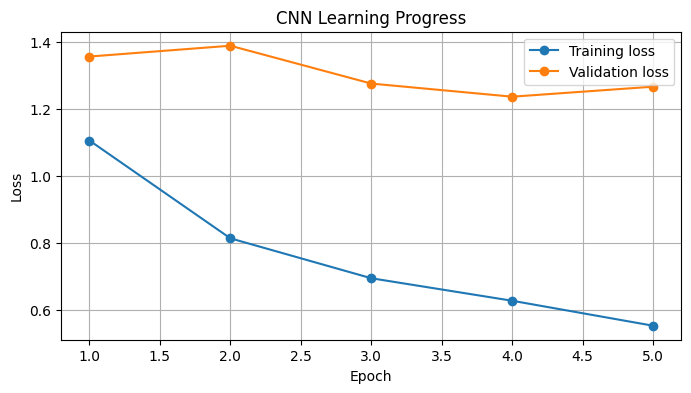

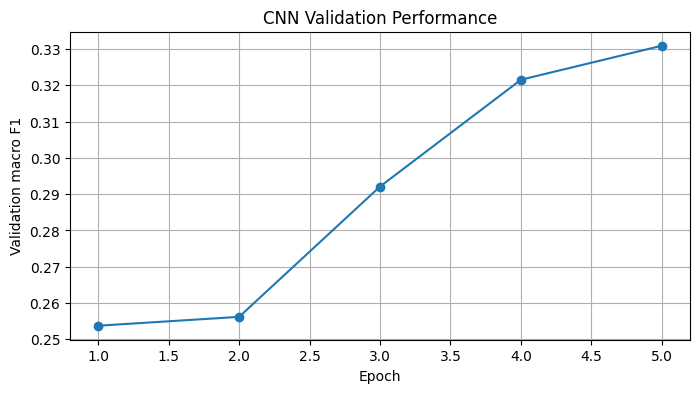

In [169]:
# Plot training loss, validation loss, and validation macro F1
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Learning Progress")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation macro F1")
plt.title("CNN Validation Performance")
plt.grid(True)
plt.show()

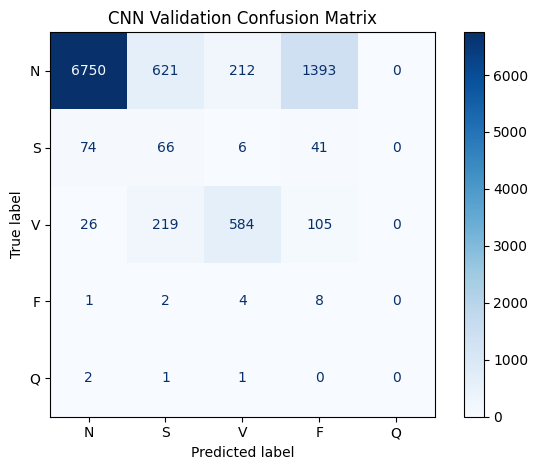

In [170]:
# Plot the CNN validation confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val_id,
    y_val_pred,
    labels=[0, 1, 2, 3, 4],
    display_labels=class_names,
    cmap="Blues",
    values_format="d"
)

plt.title("CNN Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [171]:
# Save training history and the best CNN checkpoint
history_df.to_csv("cnn_training_history.csv", index=False)
torch.save(cnn_model.state_dict(), "best_ecg_cnn.pt")

print("Saved cnn_training_history.csv")
print("Saved best_ecg_cnn.pt")

Saved cnn_training_history.csv
Saved best_ecg_cnn.pt


In [172]:
# Download the history and trained model
from google.colab import files

files.download("cnn_training_history.csv")
files.download("best_ecg_cnn.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [173]:
# Count the actual heartbeat classes in validation
from collections import Counter

for class_id, count in sorted(Counter(y_val_id).items()):
    print(f"{class_names[class_id]}: {count} beats")

N: 8976 beats
S: 187 beats
V: 934 beats
F: 15 beats
Q: 4 beats


In [174]:
# Calculate validation metrics for the best CNN
from sklearn.metrics import accuracy_score, f1_score, recall_score

print("Validation accuracy:", round(accuracy_score(y_val_id, y_val_pred), 4))
print("Validation macro F1:", round(f1_score(
    y_val_id, y_val_pred, average="macro", zero_division=0
), 4))

# Show recall for each class
recalls = recall_score(
    y_val_id, y_val_pred,
    labels=[0, 1, 2, 3, 4],
    average=None,
    zero_division=0
)

for name, value in zip(class_names, recalls):
    print(f"{name} recall: {value:.4f}")

Validation accuracy: 0.7323
Validation macro F1: 0.3309
N recall: 0.7520
S recall: 0.3529
V recall: 0.6253
F recall: 0.5333
Q recall: 0.0000


In [175]:
# Find the epoch with the highest validation macro F1
best_row = history_df.loc[history_df["val_macro_f1"].idxmax()]

print("Best epoch:", int(best_row["epoch"]))
print("Best validation macro F1:", round(best_row["val_macro_f1"], 4))
print("Training loss:", round(best_row["train_loss"], 4))
print("Validation loss:", round(best_row["val_loss"], 4))

Best epoch: 5
Best validation macro F1: 0.3309
Training loss: 0.5516
Validation loss: 1.2663


In [176]:
# Save the current CNN experiment summary
experiment = pd.DataFrame([{
    "model": "1D CNN + RR features",
    "epochs": len(history_df),
    "best_epoch": int(best_row["epoch"]),
    "best_validation_macro_f1": best_row["val_macro_f1"],
    "training_examples": len(y_train_id),
    "validation_examples": len(y_val_id),
    "test_examples": len(y_test),
    "random_seed": 42
}])

experiment.to_csv("cnn_experiment_summary.csv", index=False)

print(experiment.to_string(index=False))

               model  epochs  best_epoch  best_validation_macro_f1  training_examples  validation_examples  test_examples  random_seed
1D CNN + RR features       5           5                  0.330885              40886                10116          47557           42


In [177]:
# Verify that training, validation, and test record lists are disjoint
print("Training-validation overlap:", set(TRAIN_RECORDS) & set(VAL_RECORDS))
print("Training-test overlap:", set(TRAIN_RECORDS) & set(DS2))
print("Validation-test overlap:", set(VAL_RECORDS) & set(DS2))

# Confirm the known paired record is excluded from testing
print("Record 201 in training:", "201" in TRAIN_RECORDS)
print("Record 202 in testing:", "202" in DS2)

Training-validation overlap: set()
Training-test overlap: set()
Validation-test overlap: set()
Record 201 in training: True
Record 202 in testing: False


In [178]:
# Show precision, recall, and F1 for every validation class
from sklearn.metrics import classification_report

print(classification_report(
    y_val_id,
    y_val_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

           N       0.98      0.75      0.85      8976
           S       0.07      0.35      0.12       187
           V       0.72      0.63      0.67       934
           F       0.01      0.53      0.01        15
           Q       0.00      0.00      0.00         4

    accuracy                           0.73     10116
   macro avg       0.36      0.45      0.33     10116
weighted avg       0.94      0.73      0.82     10116



In [179]:
# Save the validation metrics in a CSV file
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_val_id, y_val_pred,
    labels=[0, 1, 2, 3, 4],
    zero_division=0
)

metrics_df = pd.DataFrame({
    "class": class_names,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support
})

metrics_df.to_csv("cnn_validation_metrics.csv", index=False)
print(metrics_df)

  class  precision    recall  f1_score  support
0     N   0.984970  0.752005  0.852865     8976
1     S   0.072607  0.352941  0.120438      187
2     V   0.723668  0.625268  0.670879      934
3     F   0.005171  0.533333  0.010243       15
4     Q   0.000000  0.000000  0.000000        4


In [180]:
# Count how often the CNN predicts each class
pred_counts = Counter(y_val_pred)

for class_id, name in enumerate(class_names):
    print(f"{name}: {pred_counts.get(class_id, 0)} predictions")

N: 6853 predictions
S: 909 predictions
V: 807 predictions
F: 1547 predictions
Q: 0 predictions


In [181]:
# Count how often the CNN predicts each class
pred_counts = Counter(y_val_pred)

for class_id, name in enumerate(class_names):
    print(f"{name}: {pred_counts.get(class_id, 0)} predictions")

N: 6853 predictions
S: 909 predictions
V: 807 predictions
F: 1547 predictions
Q: 0 predictions


In [182]:
# Verify that the best CNN model was saved
import os

print("Model file exists:", os.path.exists("best_ecg_cnn.pt"))

if os.path.exists("best_ecg_cnn.pt"):
    print("Model file size:", round(os.path.getsize("best_ecg_cnn.pt") / 1024, 2), "KB")

Model file exists: True
Model file size: 48.15 KB


In [183]:
# Save a readable summary of the current experiment
summary = f"""
ECG Arrhythmia Detection — CNN Experiment

Model: 1D CNN with RR interval features
Training examples: {len(y_train_id)}
Validation examples: {len(y_val_id)}
Test examples: {len(y_test)}

Best epoch: {int(best_row['epoch'])}
Best validation macro F1: {best_row['val_macro_f1']:.4f}

Important:
- Test metrics have not yet been finalized.
- Patient-level independence must be verified.
- This is a research prototype, not a clinical diagnostic tool.
"""

with open("project_checkpoint.txt", "w") as file:
    file.write(summary)

print("Saved project_checkpoint.txt")

Saved project_checkpoint.txt


In [184]:
# Check that the four excluded records aren't in our datasets
paced_records = {"102", "104", "107", "217"}

print("Paced records in training:", paced_records & set(TRAIN_RECORDS))
print("Paced records in validation:", paced_records & set(VAL_RECORDS))
print("Paced records in testing:", paced_records & set(DS2))

Paced records in training: set()
Paced records in validation: set()
Paced records in testing: set()


In [185]:
# Check that the three record groups are separate
print("Train-validation overlap:", set(TRAIN_RECORDS) & set(VAL_RECORDS))
print("Train-test overlap:", set(TRAIN_RECORDS) & set(DS2))
print("Validation-test overlap:", set(VAL_RECORDS) & set(DS2))

Train-validation overlap: set()
Train-test overlap: set()
Validation-test overlap: set()


In [186]:
# Confirm how records 201 and 202 are handled
print("201 in training:", "201" in TRAIN_RECORDS)
print("201 in validation:", "201" in VAL_RECORDS)
print("202 in testing:", "202" in DS2)

201 in training: True
201 in validation: False
202 in testing: False


In [187]:
# Count the heartbeat classes available for training
from collections import Counter

train_counts = Counter(y_train)

for label in ["N", "S", "V", "F", "Q"]:
    print(f"{label}: {train_counts.get(label, 0)} beats")

N: 36840 beats
S: 789 beats
V: 2854 beats
F: 399 beats
Q: 4 beats


In [188]:
# Identify classes missing from the training dataset
missing_classes = [
    label for label in ["N", "S", "V", "F", "Q"]
    if train_counts.get(label, 0) == 0
]

print("Missing training classes:", missing_classes)
print("All classes represented:", len(missing_classes) == 0)

Missing training classes: []
All classes represented: True


In [189]:
# Count the heartbeat classes used to evaluate the CNN
val_counts = Counter(y_val)

for label in ["N", "S", "V", "F", "Q"]:
    print(f"{label}: {val_counts.get(label, 0)} beats")

N: 8976 beats
S: 187 beats
V: 934 beats
F: 15 beats
Q: 4 beats


In [190]:
# Compare class counts across the three datasets
import pandas as pd

class_summary = pd.DataFrame({
    "Training": Counter(y_train),
    "Validation": Counter(y_val),
    "Testing": Counter(y_test)
}).fillna(0).astype(int)

print(class_summary)

   Training  Validation  Testing
N     36840        8976    41967
Q         4           4        7
S       789         187     1995
V      2854         934     3201
F       399          15      387


In [191]:
# Save class counts for the project README
class_summary.to_csv("class_distribution_summary.csv")

print("Saved class_distribution_summary.csv")

Saved class_distribution_summary.csv


In [192]:
# Download the class distribution table
from google.colab import files

files.download("class_distribution_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [193]:
# Compare each class with the most common class
counts = Counter(y_train)
largest_class = max(counts.values())

for label in ["N", "S", "V", "F", "Q"]:
    count = counts.get(label, 0)
    ratio = largest_class / count if count else float("inf")
    print(f"{label}: {count} beats | imbalance ratio: {ratio:.1f}:1")

N: 36840 beats | imbalance ratio: 1.0:1
S: 789 beats | imbalance ratio: 46.7:1
V: 2854 beats | imbalance ratio: 12.9:1
F: 399 beats | imbalance ratio: 92.3:1
Q: 4 beats | imbalance ratio: 9210.0:1


In [194]:
# Verify the saved model matches the best validation checkpoint
saved_state = torch.load(
    "best_ecg_cnn.pt",
    map_location=device,
    weights_only=True
)

cnn_model.load_state_dict(saved_state)

print("Loaded the saved CNN checkpoint.")
print("Best validation macro F1:", round(best_f1, 4))

Loaded the saved CNN checkpoint.
Best validation macro F1: 0.3309


In [195]:
# Save a compact experiment summary
summary_df = pd.DataFrame([{
    "model": "1D CNN + RR",
    "training_beats": len(y_train),
    "validation_beats": len(y_val),
    "test_beats": len(y_test),
    "validation_macro_f1": best_f1,
    "training_classes": len(set(y_train)),
    "validation_classes": len(set(y_val))
}])

summary_df.to_csv("cnn_summary.csv", index=False)
print(summary_df.to_string(index=False))

      model  training_beats  validation_beats  test_beats  validation_macro_f1  training_classes  validation_classes
1D CNN + RR           40886             10116       47557             0.330885                 5                   5


In [196]:
# Import Random Forest and tools for evaluating its predictions
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

In [197]:
# Combine each heartbeat waveform with its two RR-interval features
X_train_rf = np.hstack([X_train_norm, rr_train_scaled])
X_val_rf = np.hstack([X_val_norm, rr_val_scaled])

# Check the number of beats and features
print("Training data shape:", X_train_rf.shape)
print("Validation data shape:", X_val_rf.shape)

Training data shape: (40886, 254)
Validation data shape: (10116, 254)


In [198]:
# Create a Random Forest model that accounts for class imbalance
rf_model = RandomForestClassifier(
    n_estimators=100,            # Build 100 decision trees
    class_weight="balanced",     # Give rare classes more importance
    random_state=42,             # Make results reproducible
    n_jobs=-1                    # Use available CPU cores
)

# Train using only the training data
rf_model.fit(X_train_rf, y_train)

# Predict heartbeat classes in the validation data
y_val_rf_pred = rf_model.predict(X_val_rf)

# Display precision, recall, and F1-score for each class
print(classification_report(
    y_val,
    y_val_rf_pred,
    labels=["N", "S", "V", "F", "Q"],
    zero_division=0
))

# Calculate the overall macro F1-score
rf_val_f1 = f1_score(
    y_val,
    y_val_rf_pred,
    labels=["N", "S", "V", "F", "Q"],
    average="macro",
    zero_division=0
)

print("Random Forest validation macro F1:", round(rf_val_f1, 4))

              precision    recall  f1-score   support

           N       0.93      0.93      0.93      8976
           S       1.00      0.01      0.02       187
           V       0.49      0.56      0.53       934
           F       0.01      0.07      0.01        15
           Q       0.00      0.00      0.00         4

    accuracy                           0.88     10116
   macro avg       0.49      0.31      0.30     10116
weighted avg       0.89      0.88      0.87     10116

Random Forest validation macro F1: 0.2983


In [199]:
# Count training examples for each heartbeat class
from collections import Counter

for label, count in sorted(Counter(y_train).items()):
    print(f"Class {label}: {count} beats")

Class F: 399 beats
Class N: 36840 beats
Class Q: 4 beats
Class S: 789 beats
Class V: 2854 beats


In [200]:
# Display the class weights used by the CNN
for label, weight in zip(class_names, weights):
    print(f"Class {label}: weight = {weight:.2f}")

Class N: weight = 0.22
Class S: weight = 10.36
Class V: weight = 2.87
Class F: weight = 20.49
Class Q: weight = 2044.30


In [201]:
# Count each class in training, validation, and testing
class_counts = pd.DataFrame({
    "Training": Counter(y_train),
    "Validation": Counter(y_val),
    "Testing": Counter(y_test)
}).fillna(0).astype(int)

print(class_counts)

   Training  Validation  Testing
N     36840        8976    41967
Q         4           4        7
S       789         187     1995
V      2854         934     3201
F       399          15      387


In [202]:
# Reload training data using the corrected RR calculation
X_train, y_train, rr_train = load_group_with_rr(TRAIN_RECORDS)

# Reload validation data using the corrected RR calculation
X_val, y_val, rr_val = load_group_with_rr(VAL_RECORDS)

# Display the updated data shapes
print("Training:", X_train.shape, y_train.shape, rr_train.shape)
print("Validation:", X_val.shape, y_val.shape, rr_val.shape)

101 : 1864 beats
106 : 2027 beats
108 : 1762 beats
109 : 2531 beats
112 : 2538 beats
114 : 1879 beats
115 : 1952 beats
116 : 2411 beats
119 : 1987 beats
122 : 2475 beats
124 : 1618 beats
201 : 1963 beats
205 : 2655 beats
207 : 1859 beats
208 : 2953 beats
209 : 3004 beats
215 : 3362 beats
220 : 2046 beats
118 : 2277 beats
203 : 2980 beats
223 : 2604 beats
230 : 2255 beats
Training: (40886, 252) (40886,) (40886, 2)
Validation: (10116, 252) (10116,) (10116, 2)


In [203]:
# Calculate waveform normalization values from training data
wave_mean = X_train.mean()
wave_std = X_train.std()

# Apply the same normalization to all datasets
X_train_norm = ((X_train - wave_mean) / (wave_std + 1e-8)).astype(np.float32)
X_val_norm = ((X_val - wave_mean) / (wave_std + 1e-8)).astype(np.float32)

# Add the channel dimension required by the CNN
X_train_cnn = X_train_norm[:, np.newaxis, :]
X_val_cnn = X_val_norm[:, np.newaxis, :]

print("Training CNN input:", X_train_cnn.shape)
print("Validation CNN input:", X_val_cnn.shape)

Training CNN input: (40886, 1, 252)
Validation CNN input: (10116, 1, 252)


In [204]:
from sklearn.preprocessing import StandardScaler

# Fit RR scaling using training data only
rr_scaler = StandardScaler()
rr_train_scaled = rr_scaler.fit_transform(rr_train).astype(np.float32)
rr_val_scaled = rr_scaler.transform(rr_val).astype(np.float32)

# Convert heartbeat labels into numeric class IDs
class_names = ["N", "S", "V", "F", "Q"]
label_to_id = {label: i for i, label in enumerate(class_names)}

y_train_id = np.array([label_to_id[v] for v in y_train])
y_val_id = np.array([label_to_id[v] for v in y_val])

print("Labels prepared:", len(y_train_id), len(y_val_id))

Labels prepared: 40886 10116


In [205]:
from torch.utils.data import TensorDataset, DataLoader

# Package waveform, RR features, and labels together
train_dataset = TensorDataset(
    torch.tensor(X_train_cnn),
    torch.tensor(rr_train_scaled),
    torch.tensor(y_train_id, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_cnn),
    torch.tensor(rr_val_scaled),
    torch.tensor(y_val_id, dtype=torch.long)
)

# Create batches for model training and validation
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

print("Training and validation loaders are ready.")

Training and validation loaders are ready.


In [209]:
# Restore the model from its best validation checkpoint
cnn_model = ECG_CNN().to(device)
cnn_model.load_state_dict(
    torch.load("best_ecg_cnn.pt", map_location=device, weights_only=True)
)

# Use evaluation mode for predictions
cnn_model.eval()

print("Best CNN model loaded.")

Best CNN model loaded.


In [210]:
# Reload test beats using the corrected RR calculation
X_test, y_test, rr_test = load_group_with_rr(DS2)

# Normalize waveforms using training-set statistics
X_test_norm = ((X_test - wave_mean) / (wave_std + 1e-8)).astype(np.float32)
X_test_cnn = X_test_norm[:, np.newaxis, :]

# Scale RR features using the scaler fitted on training data
rr_test_scaled = rr_scaler.transform(rr_test).astype(np.float32)

# Convert test labels to numeric class IDs
y_test_id = np.array([label_to_id[v] for v in y_test])

# Package the test data into batches
test_dataset = TensorDataset(
    torch.tensor(X_test_cnn),
    torch.tensor(rr_test_scaled),
    torch.tensor(y_test_id, dtype=torch.long)
)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print("Test beats:", len(y_test_id))
print("Test inputs:", X_test_cnn.shape, rr_test_scaled.shape)

100 : 2271 beats
103 : 2083 beats
105 : 2572 beats
111 : 2124 beats
113 : 1794 beats
117 : 1534 beats
121 : 1862 beats
123 : 1517 beats
200 : 2600 beats
210 : 2648 beats
212 : 2747 beats
213 : 3250 beats
214 : 2260 beats
219 : 2154 beats
221 : 2427 beats
222 : 2481 beats
228 : 2053 beats
231 : 1570 beats
232 : 1780 beats
233 : 3077 beats
234 : 2753 beats
Test beats: 47557
Test inputs: (47557, 1, 252) (47557, 2)


In [211]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import pandas as pd

# Predict the test heartbeat classes without updating the model
cnn_model.eval()
y_test_pred = []

with torch.no_grad():
    for waveform, rr, labels in test_loader:
        outputs = cnn_model(waveform.to(device), rr.to(device))
        y_test_pred.extend(outputs.argmax(dim=1).cpu().numpy())

# Calculate the final test macro F1
test_macro_f1 = f1_score(
    y_test_id, y_test_pred, average="macro", zero_division=0
)

print("Test macro F1:", round(test_macro_f1, 4))
print("\nClassification report:")
print(classification_report(
    y_test_id,
    y_test_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Display the confusion matrix with readable class labels
cm = confusion_matrix(y_test_id, y_test_pred, labels=list(range(len(class_names))))
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=class_names, columns=class_names))

Test macro F1: 0.3282

Classification report:
              precision    recall  f1-score   support

           N       0.96      0.73      0.83     41967
           S       0.13      0.12      0.13      1995
           V       0.44      0.92      0.60      3201
           F       0.05      0.82      0.09       387
           Q       0.00      0.00      0.00         7

    accuracy                           0.72     47557
   macro avg       0.32      0.52      0.33     47557
weighted avg       0.88      0.72      0.78     47557


Confusion matrix (rows = actual, columns = predicted):
       N     S     V     F  Q
N  30706  1493  3350  6418  0
S   1392   248   282    73  0
V     29   144  2930    98  0
F     17     6    45   319  0
Q      0     0     6     1  0
